In [79]:
import pandas as pd
import polars as pl
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,roc_curve, auc,mean_squared_error,recall_score,
precision_recall_curve,log_loss,roc_auc_score,average_precision_score,f1_score)
from sklearn.model_selection import train_test_split,RepeatedKFold,cross_val_score,TimeSeriesSplit,GridSearchCV
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPRegressor,MLPClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from tempfile import mkdtemp

In [80]:
PATH = "../data/processed/statcast_2022.parquet"
data = pl.read_parquet(PATH)

In [81]:
data = data.filter(pl.col("description").is_in(["called_strike", "ball"]) & 
                (pl.col("plate_x").is_not_null()) &
                (pl.col("sz_top").is_not_null())
                )
data = data.with_columns((pl.col("is_missed_ball") | pl.col("is_missed_strike")).alias("wrong_call"))
data = data.to_pandas()

In [82]:
pitch_mapping = {
    # Fastballs (Velocity & Movement variations)
    "FF": "Fastball",  # Four-Seam Fastball
    "SI": "Fastball",  # Sinker
    "FC": "Fastball",  # Cutter
    "FA": "Fastball",  # Other Fastball

    # Sliders (Horizontal movement)
    "SL": "Slider",    # TSlider
    "ST": "Slider",    # Sweeper
    "SV": "Slider",    # Slurve

    # Curveballs
    "CU": "Curveball", # Traditional Curveball
    "KC": "Curveball", # Knuckle-Curve
    "CS": "Curveball", # Slow Curve

    # Changeups
    "CH": "Changeup",  # Traditional Changeup
    "FS": "Changeup",  # Splitter (Finger-Split)
    "FO": "Changeup",  # Forkball
    "SC": "Changeup",  # Screwball (Fades opposite of a slider)

    # Junk
    "EP": "Junk",      # Eephus (Ultra-slow utility pitch)
    "KN": "Junk"       # Knuckleball
}

data["pitch_cat"] = data["pitch_type"].map(pitch_mapping)
data["count"] = data["balls"].astype(str) + "-" + data["strikes"].astype(str)
data["same_hand"] = (data["stand"] == data["p_throws"]).astype(int)
data["wrong_call"] = data["is_missed_ball"] | data["is_missed_strike"]
data['call'] = data['description']
data["month"] = pd.to_datetime(data["game_date"]).dt.month
data["zone"] = data["zone"].astype(int).astype(str) 
data["pitcher"] = data["pitcher"].astype(int).astype(str) 
data["batter"] = data["batter"].astype(int).astype(str) 
data["called_strike"] = (data["description"] == "called_strike").astype(int)

In [83]:
#data.info(verbose=True)

In [84]:
feature_cols = [
    "release_speed",
    "release_spin_rate",
    "pitch_cat",
    "zone",
    "balls",
    "strikes",
    "inning",
    "outs_when_up",
    "inning_topbot",
    "stand",
    "p_throws",
    "n_thruorder_pitcher",
    "sz_top",
    "sz_bot",
         
    "pitcher",
    "batter",
    "pitch_number",
    "pitcher_days_since_prev_game"

]

response_col = [
    #"is_missed_ball",
    #"is_missed_strike",
    "wrong_call"
    ][0]

In [91]:
X = data[feature_cols]
y = data[response_col]

split = int(len(X) * 0.8)
train_features, test_features = X.iloc[:split], X.iloc[split:]
train_response, test_response = y.iloc[:split], y.iloc[split:]

cat_cols = ["pitch_cat", "zone", "inning_topbot", "stand", "p_throws","pitcher","batter",]
num_cols = [c for c in feature_cols if c not in cat_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", RobustScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=300), cat_cols),
])

train_error = []
test_error = []

cv = TimeSeriesSplit(n_splits=5)

mlp_model = MLPClassifier(max_iter=200, random_state=6740)

pipe = Pipeline(steps=[
    ("prep", preprocess),
    ("mlp", mlp_model),])

param_grid = {
    'mlp__hidden_layer_sizes': [(50, 20), (100, 50)],
    'mlp__alpha': [1e-3, 1e-1],
    #'mlp__learning_rate_init': [0.001, 0.003, 0.01],
    'mlp__batch_size': [256],
    'mlp__early_stopping': [True]
}

 
search = GridSearchCV(pipe, param_grid, cv=cv, scoring="average_precision", n_jobs=-1)
search.fit(train_features, train_response)

print("Best params:", search.best_params_)
print("Best CV PR-AUC:", search.best_score_)

Best params: {'mlp__alpha': 0.001, 'mlp__batch_size': 256, 'mlp__early_stopping': True, 'mlp__hidden_layer_sizes': (50, 20)}
Best CV PR-AUC: 0.23198927387570373


In [92]:
final_model = clone(pipe).set_params(**search.best_params_)
final_model.fit(train_features, train_response)

mlp_train_probs = final_model.predict_proba(train_features)[:, 1]
mlp_test_probs  = final_model.predict_proba(test_features)[:, 1]

pr, rc, th = precision_recall_curve(train_response, mlp_train_probs)
thr = th[np.argmax((2 * pr * rc / (pr + rc + 1e-12))[:-1])]
mlp_train_preds = (mlp_train_probs >= thr).astype(int)
mlp_test_preds  = (mlp_test_probs  >= thr).astype(int)

for name, yt, pp, pl in [("Train", train_response, mlp_train_probs, mlp_train_preds),
                         ("Test",  test_response,  mlp_test_probs,  mlp_test_preds)]:
    print(f"MLP {name}: LogLoss {log_loss(yt, pp):.4f} | ROC-AUC {roc_auc_score(yt, pp):.4f} | "
          f"PR-AUC {average_precision_score(yt, pp):.4f} | F1 {f1_score(yt, pl):.4f} | base rate {yt.mean():.3f}")

results = pd.DataFrame({
    'actual':     pd.concat([train_response, test_response]).values,
    'pred_prob':  np.concatenate([mlp_train_probs, mlp_test_probs]),
    'pred_label': np.concatenate([mlp_train_preds, mlp_test_preds]),
    'split':      ['train'] * len(train_response) + ['test'] * len(test_response)})

MLP Train: LogLoss 0.3075 | ROC-AUC 0.7539 | PR-AUC 0.2583 | F1 0.3401 | base rate 0.111
MLP Test: LogLoss 0.3035 | ROC-AUC 0.7475 | PR-AUC 0.2351 | F1 0.3269 | base rate 0.108


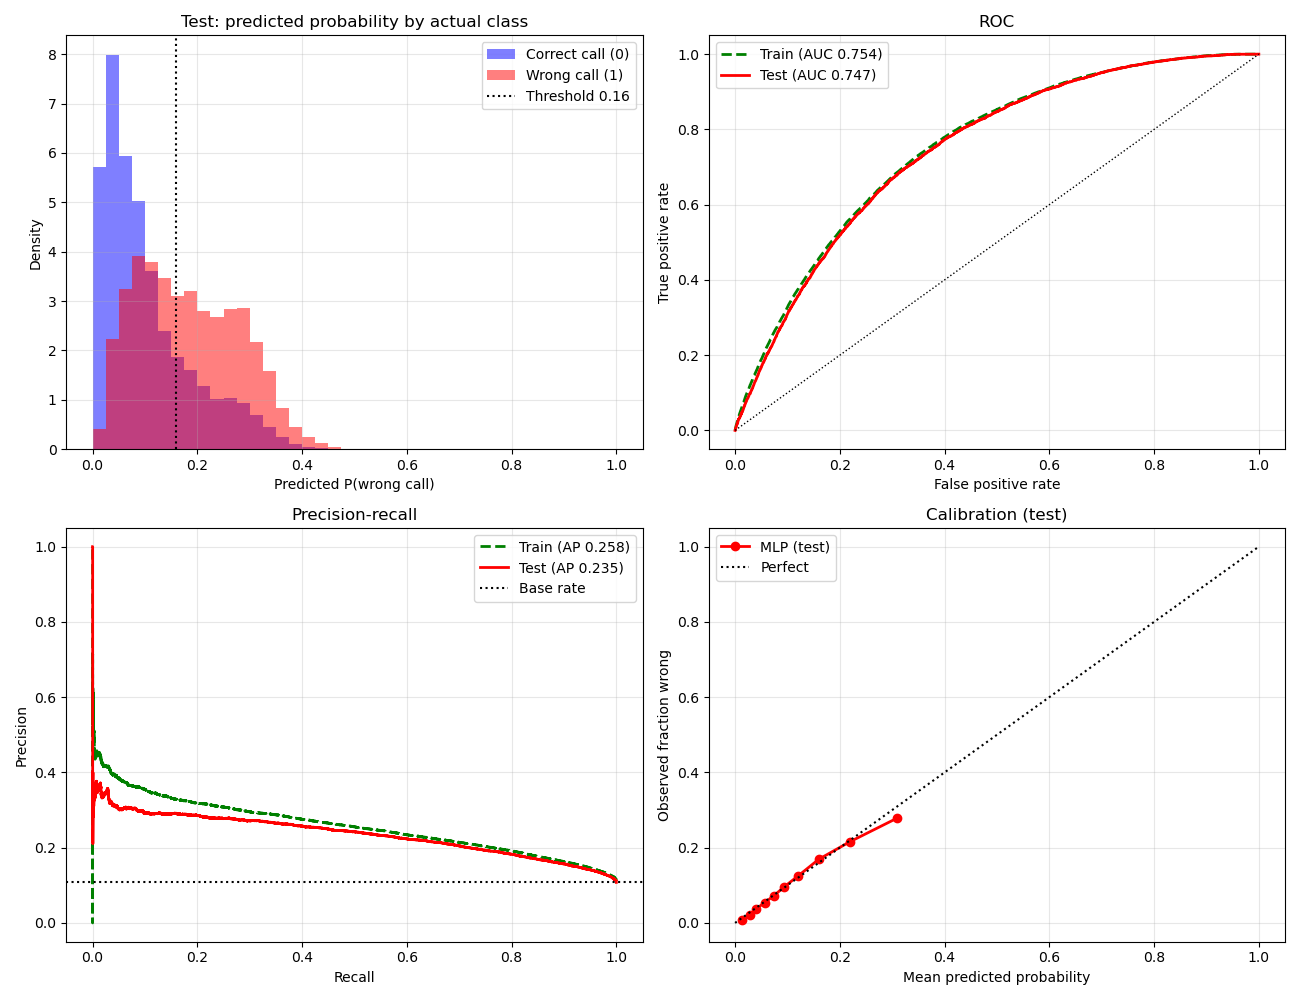

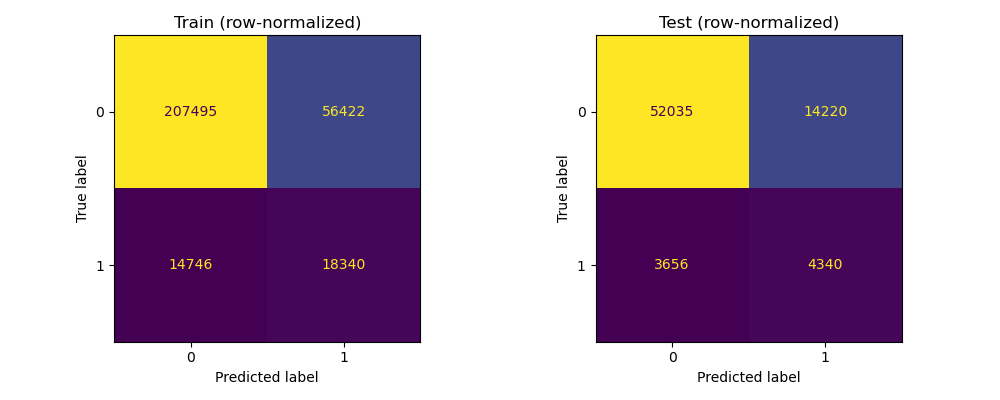

In [93]:
%matplotlib widget
fig, ax = plt.subplots(2, 2, figsize=(13, 10))

bins = np.linspace(0, 1, 41)
for cls, c, lbl in [(0, 'b', 'Correct call (0)'), (1, 'r', 'Wrong call (1)')]:
    ax[0, 0].hist(mlp_test_probs[test_response.values == cls], bins=bins, color=c, alpha=.5, density=True, label=lbl)
ax[0, 0].axvline(thr, color='black', linestyle=':', linewidth=1.5, label=f'Threshold {thr:.2f}')
ax[0, 0].set(xlabel='Predicted P(wrong call)', ylabel='Density', title='Test: predicted probability by actual class')
ax[0, 0].legend()

for yt, pp, st, lbl in [(train_response, mlp_train_probs, 'g--', 'Train'), (test_response, mlp_test_probs, 'r-', 'Test')]:
    f, t, _ = roc_curve(yt, pp)
    ax[0, 1].plot(f, t, st, linewidth=2, label=f'{lbl} (AUC {roc_auc_score(yt, pp):.3f})')
ax[0, 1].plot([0, 1], [0, 1], 'k:', linewidth=1)
ax[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC'); ax[0, 1].legend()

for yt, pp, st, lbl in [(train_response, mlp_train_probs, 'g--', 'Train'), (test_response, mlp_test_probs, 'r-', 'Test')]:
    p_, r_, _ = precision_recall_curve(yt, pp)
    ax[1, 0].plot(r_, p_, st, linewidth=2, label=f'{lbl} (AP {average_precision_score(yt, pp):.3f})')
ax[1, 0].axhline(test_response.mean(), color='black', linestyle=':', linewidth=1.5, label='Base rate')
ax[1, 0].set(xlabel='Recall', ylabel='Precision', title='Precision-recall'); ax[1, 0].legend()

fp, mp = calibration_curve(test_response, mlp_test_probs, n_bins=10, strategy='quantile')
ax[1, 1].plot(mp, fp, 'ro-', linewidth=2, label='MLP (test)')
ax[1, 1].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Perfect')
ax[1, 1].set(xlabel='Mean predicted probability', ylabel='Observed fraction wrong', title='Calibration (test)')
ax[1, 1].legend()

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figs/MLP_WrongCall_Diagnostics.png", dpi=300)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yt, pl, ttl in [(ax[0], train_response, mlp_train_preds, 'Train'), (ax[1], test_response, mlp_test_preds, 'Test')]:
    ConfusionMatrixDisplay.from_predictions(yt, pl, ax=a, colorbar=False, 
    # normalize='true',
    #  values_format='.2f'
     )
    a.set_title(f'{ttl} (row-normalized)')
plt.tight_layout()
plt.savefig("../figs/MLP_WrongCall_Confusion.png", dpi=300)
plt.show()

In [94]:
# Test-set predictions created in the MLP model cell
y_test = test_response
pred_label = mlp_test_preds
pred_prob = mlp_test_probs

print(f"Accuracy:   {accuracy_score(y_test, pred_label):.3f}")
print(f"Precision:  {precision_score(y_test, pred_label, zero_division=0):.3f}")
print(f"Recall:     {recall_score(y_test, pred_label, zero_division=0):.3f}")
print(f"F1 score:   {f1_score(y_test, pred_label, zero_division=0):.3f}")
print(f"ROC-AUC:    {roc_auc_score(y_test, pred_prob):.3f}")

Accuracy:   0.759
Precision:  0.234
Recall:     0.543
F1 score:   0.327
ROC-AUC:    0.747


In [95]:
import os

OUT_DIR = "../results/raw"
os.makedirs(OUT_DIR, exist_ok=True)

# `results` was already built after the model fit cell; reuse it.
preds_df = results.copy()

preds_path = os.path.join(OUT_DIR, "mlp_predictions_vs_actuals.csv")
preds_df.to_csv(preds_path, index=False)
print(f"Saved {len(preds_df):,} rows -> {preds_path}")
print(preds_df.head())

Saved 371,254 rows -> ../results/raw\mlp_predictions_vs_actuals.csv
   actual  pred_prob  pred_label  split
0       0   0.137620           0  train
1       0   0.160673           1  train
2       0   0.025457           0  train
3       0   0.203159           1  train
4       0   0.108713           0  train


In [96]:
OUT_DIR = "../results/stats"
os.makedirs(OUT_DIR, exist_ok=True)
def _metric_row(y_true, prob, pred, threshold):
    return {
        "threshold":  threshold,
        "log_loss":   log_loss(y_true, prob),
        "roc_auc":    roc_auc_score(y_true, prob),
        "pr_auc":     average_precision_score(y_true, prob),
        "accuracy":   accuracy_score(y_true, pred),
        "precision":  precision_score(y_true, pred, zero_division=0),
        "recall":     recall_score(y_true, pred, zero_division=0),
        "f1":         f1_score(y_true, pred, zero_division=0),
        "base_rate":  float(np.mean(y_true)),
        "n_rows":     len(y_true),
    }

metrics_df = pd.DataFrame([
    {"split": "train", **_metric_row(train_response, mlp_train_probs, mlp_train_preds, thr)},
    {"split": "test",  **_metric_row(test_response,  mlp_test_probs,  mlp_test_preds,  thr)},
])

metrics_path = os.path.join(OUT_DIR, "mlp_metrics.csv")
metrics_df.to_csv(metrics_path, index=False)
print(f"Saved metrics -> {metrics_path}")
display(metrics_df)

Saved metrics -> ../results/stats\mlp_metrics.csv


,split,threshold,log_loss,roc_auc,pr_auc,accuracy,precision,recall,f1,base_rate,n_rows
0,train,0.159447,0.307492,0.753892,0.258340,0.760380,0.245312,0.554313,0.340108,0.111400,297003
1,test,0.159447,0.303483,0.747453,0.235141,0.759249,0.233836,0.542771,0.326856,0.107689,74251
